In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("UCI_Credit_Card.csv")
df = df.rename(columns={'default.payment.next.month': 'def_pay', 'PAY_0': 'PAY_1'})

In [3]:
# Drop "ID" column.
data=df.drop(['ID'], axis=1)
print(f"There are {data.duplicated().sum()} duplicate rows in the data set.")
# Duplicate rows are removed.
df = df[~data.duplicated()]

There are 35 duplicate rows in the data set.


In [4]:
#  Marital status (1 = married; 2 = single; 3 = others).
df.MARRIAGE.value_counts()

df.loc[df.MARRIAGE == 0, 'MARRIAGE'] = 3
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      377
Name: count, dtype: int64

In [5]:
# Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
df.EDUCATION.value_counts() 

fil = (df.EDUCATION == 5) | (df.EDUCATION == 6) | (df.EDUCATION == 0)
df.loc[fil, 'EDUCATION'] = 4
df.EDUCATION.value_counts()

EDUCATION
2    14019
1    10563
3     4915
4      468
Name: count, dtype: int64

In [6]:
new_df = df.drop(columns=['BILL_AMT1', 'PAY_AMT6','def_pay','PAY_1','PAY_2'])
new_df = new_df.rename(columns={'PAY_3': 'July_Status', 
                        'PAY_4': 'June_Status',
                        'PAY_5': 'May_Status',
                        'PAY_6': 'April_Status',
                        'BILL_AMT2': 'August_Bill',
                        'BILL_AMT3': 'July_Bill',
                        'BILL_AMT4': 'June_Bill',
                        'BILL_AMT5': 'May_Bill',
                        'BILL_AMT6': 'April_Bill',
                        'PAY_AMT1': 'August_Pay',
                        'PAY_AMT2': 'July_Pay',
                        'PAY_AMT3': 'June_Pay',
                        'PAY_AMT4': 'May_Pay',
                        'PAY_AMT5': 'April_Pay'})

new_df.drop(columns=['ID'], inplace=True)

new_df['SEX'] = new_df.SEX.astype('category')
new_df['EDUCATION'] = new_df.EDUCATION.astype('category')
new_df['MARRIAGE'] = new_df.MARRIAGE.astype('category')
new_df['July_Status'] = new_df.July_Status.astype('category')
new_df['June_Status'] = new_df.June_Status.astype('category')
new_df['May_Status'] = new_df.May_Status.astype('category')
new_df['April_Status'] = new_df.April_Status.astype('category')


bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
new_df["LIMIT_BAL_BIN"] = pd.cut(new_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)


# Classifier

In [7]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import  f1_score

zero_new_df = new_df.copy()
# Create a binary target for zero vs non-zero payments
zero_new_df['Is_Zero'] = (zero_new_df['August_Pay'] == 0).astype(int)

# Split the data for the classification model
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(zero_new_df.drop(columns=['August_Pay', 'Is_Zero']), zero_new_df['Is_Zero'], stratify = new_df["LIMIT_BAL_BIN"], test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train_class = scaler.fit_transform(X_train_class)
X_test_class = scaler.transform(X_test_class)

In [8]:
# Train the AdaBoost classifier
ada_model = AdaBoostClassifier(random_state=42)
ada_model.fit(X_train_class, y_train_class)

# Predict and evaluate the AdaBoost classifier
y_pred_ada_class = ada_model.predict(X_test_class)
ada_accuracy = f1_score(y_test_class, y_pred_ada_class)
print(f"AdaBoost F1 Score: {ada_accuracy}")

AdaBoost F1 Score: 0.7440406408753419


In [9]:
# Train the Random Forest classifier
forest_model = RandomForestClassifier(random_state=42, n_estimators=500, max_depth=75, min_samples_split=5, min_samples_leaf=1)
forest_model.fit(X_train_class, y_train_class)

# Predict and evaluate the Random Forest classifier
y_pred_forest_class = forest_model.predict(X_test_class)
forest_accuracy = f1_score(y_test_class, y_pred_forest_class)
print(f"Random Forest F1 Score: {forest_accuracy}")

Random Forest F1 Score: 0.7909943714821763


In [10]:
# Train the MLP classifier
mlp_model = MLPClassifier(random_state=42, hidden_layer_sizes=(20, 20), max_iter=600)
mlp_model.fit(X_train_class, y_train_class)

# Predict and evaluate the MLP classifier
y_pred_mlp_class = mlp_model.predict(X_test_class)
mlp_accuracy = f1_score(y_test_class, y_pred_mlp_class)
print(f"MLP F1 Score: {mlp_accuracy}")

MLP F1 Score: 0.6706099815157116


# Regression Models

In [34]:
X_train, X_test, y_train, y_test = train_test_split(new_df.drop(columns=['August_Pay']), new_df['August_Pay'], stratify = new_df["LIMIT_BAL_BIN"], test_size=0.3, random_state=42)
X_test_copy = X_test.copy() # for resiuals
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Simple Features

In [35]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear_simple = linear_model.predict(X_test)
print(f"Linear Regression RMSE: {root_mean_squared_error(y_test, y_pred_linear_simple)}")
print(f"Linear Regression with Classifier: {root_mean_squared_error(y_test, y_pred_linear_simple * (1 - y_pred_forest_class))}")

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
y_pred_forest_simple = forest_model.predict(X_test)
print(f"Random Forest RMSE: {root_mean_squared_error(y_test, y_pred_forest_simple)}")
print(f"Random Forest with Classifier: {root_mean_squared_error(y_test, y_pred_forest_simple * (1 - y_pred_forest_class))}")

mlp_model = MLPRegressor(random_state=42, max_iter=600, hidden_layer_sizes=(50, 25), alpha=0.01)
mlp_model.fit(X_train, y_train)
y_pred_mlp_simple = mlp_model.predict(X_test)
y_pred_mlp_simple = np.maximum(y_pred_mlp_simple, 0)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp_simple)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp_simple * (1 - y_pred_forest_class))}")

Linear Regression RMSE: 15231.35735283232
Linear Regression with Classifier: 15095.86145824381
Random Forest RMSE: 15621.191405046055
Random Forest with Classifier: 15383.586080536006
MLP RMSE: 14490.64050256074
MLP with Classifier: 14473.988284301535


# Feature Transformation & New Features

In [13]:
log_new_df = new_df.copy()
log_new_df ["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["MAX_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
log_new_df ["MAX_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
log_new_df ["MIN_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
log_new_df ["MIN_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
log_new_df ["PAY_SUM"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
log_new_df ["BILL_SUM"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
log_new_df ["CUM_PAY_JUN_JUL"] = new_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL"] = new_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_PAY_JUN_JUL_MAY"] = new_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL_MAY"] = new_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["STD_PAY"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], stratify = new_df["LIMIT_BAL_BIN"], test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [15]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
print(f"Linear Regression RMSE: {root_mean_squared_error(y_test, y_pred_linear)}")
print(f"Linear Regression with Classifier: {root_mean_squared_error(y_test, y_pred_linear * (1 - y_pred_forest_class))}")

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)
print(f"Random Forest RMSE: {root_mean_squared_error(y_test, y_pred_forest)}")
print(f"Random Forest with Classifier: {root_mean_squared_error(y_test, y_pred_forest * (1 - y_pred_forest_class))}")

mlp_model = MLPRegressor(random_state=42, max_iter=600, hidden_layer_sizes=(50, 25), alpha=0.01)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

Linear Regression RMSE: 14456.869063640439
Linear Regression with Classifier: 14351.560826678544
Random Forest RMSE: 15400.187889693752
Random Forest with Classifier: 15248.095619054428
MLP RMSE: 14449.96787844455
MLP with Classifier: 14436.902130692371


# Smote

In [16]:
log_new_df = new_df.copy()

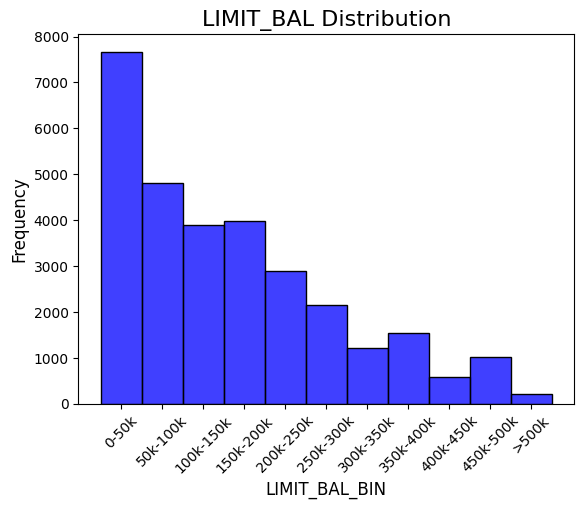

In [17]:
# Original Distribution
sns.histplot(log_new_df.LIMIT_BAL_BIN, bins=11, color="blue")
plt.title("LIMIT_BAL Distribution",fontsize=16)
plt.xlabel("LIMIT_BAL_BIN", fontsize=12)
plt.xticks(ticks=np.arange(1, 12), labels=["0-50k", "50k-100k", "100k-150k", "150k-200k", "200k-250k", "250k-300k", "300k-350k", "350k-400k", "400k-450k", "450k-500k", ">500k"], rotation=45)
plt.ylabel("Frequency", fontsize=12)
plt.show()

In [18]:
from imblearn.over_sampling import SMOTE

##########################################  SMOTE ##########################################

X_train_temp, X_test, _ , y_test = train_test_split(log_new_df, log_new_df['August_Pay'], test_size=0.3, stratify = new_df["LIMIT_BAL_BIN"], random_state=42)

# Drop columns
X_test.drop(columns=['August_Pay'], inplace=True)

print("Before SMOTE:")
print(X_train_temp.LIMIT_BAL_BIN.value_counts())

# Define numerical and categorical features
numerical_features = ["LIMIT_BAL", 
                      "August_Bill", "July_Bill", "June_Bill", "May_Bill", "April_Bill", 
                      "August_Pay", "July_Pay", "June_Pay", "May_Pay", "April_Pay"]

categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "AGE", "July_Status", "June_Status", "May_Status", "April_Status"]
target_column = "LIMIT_BAL_BIN"

# Separate numerical and categorical data
X_numerical = X_train_temp[numerical_features]
X_categorical = X_train_temp[categorical_features]  # Store categorical data separately
y = X_train_temp[target_column]

# Apply SMOTE only on numerical features
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, _ = smote.fit_resample(X_numerical, y)

# Convert to DataFrame
X_resampled_df = pd.DataFrame(X_resampled, columns=numerical_features)

# **Re-add categorical variables by sampling from original data**
X_categorical_resampled = X_categorical.sample(n=len(X_resampled_df), replace=True, random_state=42).reset_index(drop=True)

# Combine numerical, categorical, and target columns
smote_df = pd.concat([X_resampled_df, X_categorical_resampled], axis=1)

# just for checking

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

smote_df["LIMIT_BAL_BIN"] = pd.cut(smote_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

# Check new distribution
print("\nAfter SMOTE:")
print(smote_df[target_column].value_counts())

# Train-test split
y_train = smote_df.August_Pay
X_train = smote_df.drop(columns = ['August_Pay'])

cols = list(X_train.columns)
X_train = X_train[cols]
X_test = X_test[cols]


Before SMOTE:
LIMIT_BAL_BIN
1     5371
2     3372
4     2779
3     2728
5     2030
6     1507
8     1082
7      844
10     717
9      401
11     144
Name: count, dtype: int64

After SMOTE:
LIMIT_BAL_BIN
1     5371
2     5371
3     5371
4     5371
5     5371
6     5371
7     5371
8     5371
9     5371
10    5371
11    5371
Name: count, dtype: int64


# Simple Features with SMOTE

In [19]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [20]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
print(f"Linear Regression RMSE: {root_mean_squared_error(y_test, y_pred_linear)}")
print(f"Linear Regression with Classifier: {root_mean_squared_error(y_test, y_pred_linear * (1 - y_pred_forest_class))}")

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)
print(f"Random Forest RMSE: {root_mean_squared_error(y_test, y_pred_forest)}")
print(f"Random Forest with Classifier: {root_mean_squared_error(y_test, y_pred_forest * (1 - y_pred_forest_class))}")

mlp_model = MLPRegressor(random_state=42, max_iter=600, hidden_layer_sizes=(50, 25), alpha=0.01)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

Linear Regression RMSE: 15236.927714359488
Linear Regression with Classifier: 15049.920328057842
Random Forest RMSE: 16047.149417314014
Random Forest with Classifier: 15517.976177142651
MLP RMSE: 14298.840038624441
MLP with Classifier: 14201.154184749954


# Feature Transformation & New Features with SMOTE

In [21]:
# Create a new column for bins
log_new_df = new_df.copy()
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["MAX_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
log_new_df ["MAX_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
log_new_df ["MIN_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
log_new_df ["MIN_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
log_new_df ["PAY_SUM"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
log_new_df ["BILL_SUM"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
log_new_df ["CUM_PAY_JUN_JUL"] = new_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL"] = new_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_PAY_JUN_JUL_MAY"] = new_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL_MAY"] = new_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["STD_PAY"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)


In [22]:

##########################################  SMOTE ##########################################

X_train_temp, X_test, _ , y_test = train_test_split(log_new_df, log_new_df['August_Pay'], stratify = new_df["LIMIT_BAL_BIN"], test_size=0.3, random_state=42)

# Drop columns
X_test.drop(columns=['August_Pay'], inplace=True)
X_test ["LIMIT_BAL"] = np.log1p(X_test["LIMIT_BAL"]) # Log transformation

print("Before SMOTE:")
print(X_train_temp.LIMIT_BAL_BIN.value_counts())

# Define numerical and categorical features
numerical_features = ["LIMIT_BAL", 
                      "August_Bill", "July_Bill", "June_Bill", "May_Bill", "April_Bill", 
                      "August_Pay", "July_Pay", "June_Pay", "May_Pay", "April_Pay"]

categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "AGE", "July_Status", "June_Status", "May_Status", "April_Status"]
target_column = "LIMIT_BAL_BIN"

# Separate numerical and categorical data
X_numerical = X_train_temp[numerical_features]
X_categorical = X_train_temp[categorical_features]  # Store categorical data separately
y = X_train_temp[target_column]

# Apply SMOTE only on numerical features
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, _ = smote.fit_resample(X_numerical, y)

# Convert to DataFrame
X_resampled_df = pd.DataFrame(X_resampled, columns=numerical_features)

# **Re-add categorical variables by sampling from original data**
X_categorical_resampled = X_categorical.sample(n=len(X_resampled_df), replace=True, random_state=42).reset_index(drop=True)

# Combine numerical, categorical, and target columns
smote_df = pd.concat([X_resampled_df, X_categorical_resampled], axis=1)

bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
labels = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
smote_df["LIMIT_BAL_BIN"] = pd.cut(smote_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

# Check new distribution
print("\nAfter SMOTE:")
print(smote_df[target_column].value_counts())

smote_df.drop(columns=['LIMIT_BAL_BIN'], inplace=True)

# add features
smote_df ["LIMIT_BAL"] = np.log1p(smote_df["LIMIT_BAL"]) # Log transformation
smote_df ["AVG_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
smote_df ["AVG_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
smote_df ["MAX_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
smote_df ["MAX_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
smote_df ["MIN_PAY_AMT"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
smote_df ["MIN_BILL_AMT"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
smote_df ["PAY_SUM"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
smote_df ["BILL_SUM"] = smote_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
smote_df ["CUM_PAY_JUN_JUL"] = smote_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_BILL_JUN_JUL"] = smote_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_PAY_JUN_JUL_MAY"] = smote_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
smote_df ["CUM_BILL_JUN_JUL_MAY"] = smote_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
smote_df ["STD_PAY"] = smote_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].std(axis=1)

# Train-test split
y_train = smote_df.August_Pay
X_train = smote_df.drop(columns = ['August_Pay'])

cols = list(X_train.columns)
X_train = X_train[cols]
X_test = X_test[cols]

Before SMOTE:
LIMIT_BAL_BIN
1     5371
2     3372
4     2779
3     2728
5     2030
6     1507
8     1082
7      844
10     717
9      401
11     144
Name: count, dtype: int64

After SMOTE:
LIMIT_BAL_BIN
1     5371
2     5371
3     5371
4     5371
5     5371
6     5371
7     5371
8     5371
9     5371
10    5371
11    5371
Name: count, dtype: int64


In [23]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [24]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
print(f"Linear Regression RMSE: {root_mean_squared_error(y_test, y_pred_linear)}")
print(f"Linear Regression with Classifier: {root_mean_squared_error(y_test, y_pred_linear * (1 - y_pred_forest_class))}")

forest_model = RandomForestRegressor(random_state=42)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)
print(f"Random Forest RMSE: {root_mean_squared_error(y_test, y_pred_forest)}")
print(f"Random Forest with Classifier: {root_mean_squared_error(y_test, y_pred_forest * (1 - y_pred_forest_class))}")

mlp_model = MLPRegressor(random_state=42, max_iter=600, hidden_layer_sizes=(50, 25), alpha=0.01, activation= 'relu')
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
y_pred_mlp = np.maximum(y_pred_mlp, 0)
print(f"MLP RMSE: {root_mean_squared_error(y_test, y_pred_mlp)}")
print(f"MLP with Classifier: {root_mean_squared_error(y_test, y_pred_mlp * (1 - y_pred_forest_class))}")

Linear Regression RMSE: 14498.959687085238
Linear Regression with Classifier: 14377.068754421323
Random Forest RMSE: 16055.136916873533
Random Forest with Classifier: 15476.863581913403
MLP RMSE: 13605.613865201753
MLP with Classifier: 13556.367831112004


In [57]:
residuals = y_test - y_pred_mlp * (1 - y_pred_forest_class)
residuals_simple = y_test - y_pred_mlp_simple 

# Create DataFrame
temp_df = pd.DataFrame({"Bill_Range": X_test_copy['LIMIT_BAL_BIN'], 
                        "Residuals": abs(residuals), 
                        "Simple Residuals": abs(residuals_simple),
                        "Predicted": y_pred_mlp * (1 - y_pred_forest_class),
                        "Simple Predicted": y_pred_mlp,
                        "Actual": y_test})

# Compute average residuals for each bin
mean_residuals = temp_df.groupby("Bill_Range")["Residuals"].mean().reset_index()
mean_residuals_simple = temp_df.groupby("Bill_Range")["Simple Residuals"].mean().reset_index()
mean_residuals ['Simple Residuals'] = mean_residuals_simple['Simple Residuals'] 
mean_residuals['MAX'] = [50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, new_df["LIMIT_BAL"].max()]
mean_residuals['Percentage'] = round(mean_residuals['Residuals'] / mean_residuals['MAX'] * 100, 2)
mean_residuals['Simple Percentage'] = round(mean_residuals['Simple Residuals'] / mean_residuals['MAX'] * 100, 2)
mean_residuals.drop(columns=['MAX'], inplace=True)
print(mean_residuals)


   Bill_Range    Residuals  Simple Residuals  Percentage  Simple Percentage
0           1  1457.956847       1666.385627        2.92               3.33
1           2  2814.413312       2864.314708        2.81               2.86
2           3  4033.961764       3886.722174        2.69               2.59
3           4  3688.286763       3598.662561        1.84               1.80
4           5  4204.090414       4208.464536        1.68               1.68
5           6  5345.009276       5504.397978        1.78               1.83
6           7  8270.220630       9833.201471        2.36               2.81
7           8  5714.209932       6130.272159        1.43               1.53
8           9  7218.518880       7255.471158        1.60               1.61
9          10  9833.579637      10014.444290        1.97               2.00
10         11  6354.141772       9702.526260        0.64               0.97


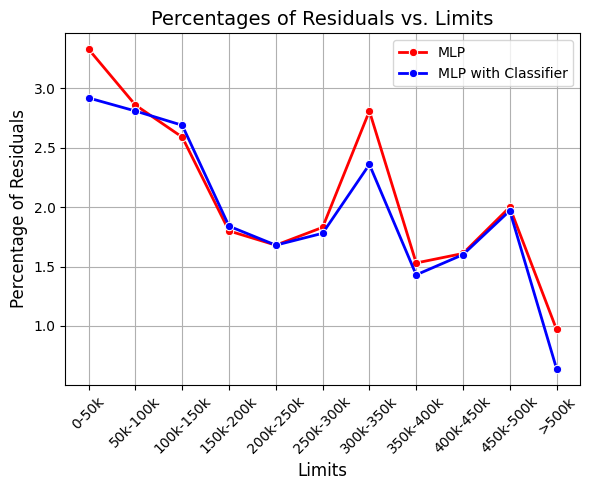

In [58]:
# Plot the average residuals and percentage of bills in each range on the same plot
fig, ax1 = plt.subplots(figsize=(6, 5))

line1 = sns.lineplot(x="Bill_Range", y="Simple Percentage", data=mean_residuals, color="red", marker="o", ax=ax1, linewidth=2, label="MLP")
line2 = sns.lineplot(x="Bill_Range", y="Percentage", data=mean_residuals, color="blue", marker="o", ax=ax1, linewidth=2, label="MLP with Classifier")
ax1.set_ylabel("Percentage of Residuals", color="black", fontsize=12)
ax1.tick_params(axis='y', labelcolor="black")
ax1.set_xlabel("Limits", color="black", fontsize=12)
ax1.set_xticklabels(labels, rotation=45)
line1.legend(loc='upper right')
plt.xticks(ticks=np.arange(1, 12), labels=["0-50k", "50k-100k", "100k-150k", "150k-200k", "200k-250k", "250k-300k", "300k-350k", "350k-400k", "400k-450k", "450k-500k", ">500k"], rotation=45)
plt.title("Percentages of Residuals vs. Limits", fontsize=14)
plt.tight_layout()
plt.grid()
plt.show()

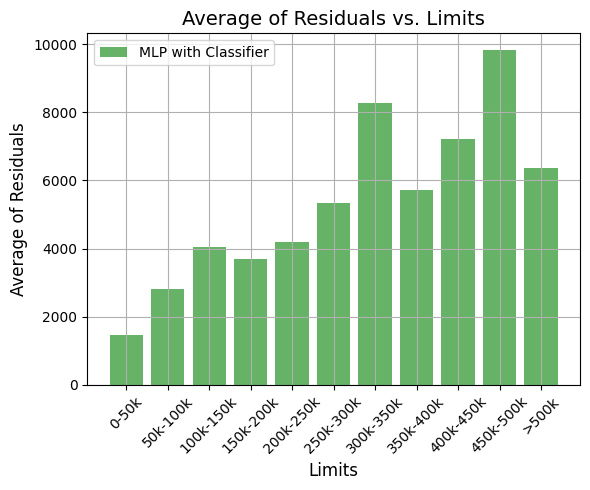

In [50]:
# Define number of bars and their x-coordinates
N = len(mean_residuals)
ind = np.arange(N)  # x locations for groups
width = 0.8 # Width of the bars

# Create figure
fig, ax = plt.subplots(figsize=(6, 5))
plt.grid()
bar1 = plt.bar(ind, mean_residuals["Residuals"], width, label="MLP with Classifier", color="green", alpha=0.6)
plt.xlabel("Limits", fontsize=12)
plt.ylabel("Average of Residuals", fontsize=12)
plt.title("Average of Residuals vs. Limits", fontsize=14)
plt.xticks(ticks=np.arange(0, 11), labels=["0-50k", "50k-100k", "100k-150k", "150k-200k", "200k-250k", "250k-300k", "300k-350k", "350k-400k", "400k-450k", "450k-500k", ">500k"], rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()